# Mini-RAG Question Answering with SQuAD v2

**Assignment:** Retrieval-Augmented Generation (RAG) using Hugging Face, semantic retrieval, and a lightweight open-source language model.

## Objectives
This notebook builds a small, inspectable RAG pipeline that:

1. Loads and explores the **SQuAD v2** dataset from Hugging Face.
2. Prepares passage documents from the dataset's `context` field.
3. Uses Sentence Transformers to embed passages and FAISS to retrieve semantically relevant context.
4. Uses the open model `google/flan-t5-small` to generate answers grounded in retrieved evidence.
5. Qualitatively evaluates answerable and unanswerable questions, identifies limitations, and summarizes possible improvements.

## 1. Install and import dependencies

The following packages provide dataset access, semantic embeddings, vector search, and text generation. If you are using a managed notebook environment such as Google Colab, install packages in the current kernel and restart it if the environment asks you to do so.


In [1]:
# Uncomment and run this cell in a fresh environment.
# %pip install -U datasets sentence-transformers faiss-cpu transformers torch pandas matplotlib


In [2]:
# Dataset loading and inspection
from collections import Counter
import random
import textwrap
import warnings

import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from sentence_transformers import SentenceTransformer
import faiss
import numpy as np
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# Set a seed for reproducible sample selection and evaluation examples.
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


PyTorch version: 2.11.0
CUDA available: False


## 2. Load and explore SQuAD v2

SQuAD v2 contains questions paired with passages (`context`). Some questions are answerable from their passage, while others are intentionally unanswerable. The latter are important because a RAG system should be able to abstain when the available evidence does not support an answer.

Each record includes:
- `id`: identifier for the question example.
- `title`: title of the source article.
- `context`: passage used as evidence.
- `question`: the question to answer.
- `answers`: a dictionary containing answer strings and their character start positions. For unanswerable examples, `answers["text"]` is empty.

The notebook also counts answerable and unanswerable records and plots the counts. This is useful context for interpreting RAG behavior: a system must not only answer when evidence is present, but should also avoid guessing when the passage does not support an answer. The chart describes the training split, not model performance.


In [3]:
# First try the canonical SQuAD v2 dataset on the Hugging Face Hub.
try:
    print("Attempting to load SQuAD v2 from the Hugging Face Hub...")
    dataset = load_dataset("rajpurkar/squad_v2")
    dataset_loading_method = 'Hugging Face Hub dataset ID: rajpurkar/squad_v2'
except Exception as hub_error:
    print("Standard Hub loading failed:", type(hub_error).__name__)
    print("Details:", str(hub_error)[:500])
    print("Falling back to the published Parquet files using load_dataset('parquet', ...).")

    dataset_files = {
        "train": (
            "https://huggingface.co/datasets/rajpurkar/squad_v2/"
            "resolve/main/squad_v2/train-00000-of-00001.parquet"
        ),
        "validation": (
            "https://huggingface.co/datasets/rajpurkar/squad_v2/"
            "resolve/main/squad_v2/validation-00000-of-00001.parquet"
        ),
    }
    dataset = load_dataset("parquet", data_files=dataset_files)
    dataset_loading_method = 'Hugging Face Datasets Parquet fallback'

print("Dataset loading method:", dataset_loading_method)
print(dataset)
print("\nTraining columns:", dataset["train"].column_names)
print("Training examples:", len(dataset["train"]))
print("Validation examples:", len(dataset["validation"]))

# Print a complete sample record to inspect the actual structure.
sample = dataset["train"][0]
print("\nSample record:")
print(sample)
print("\nField interpretation:")
print("- id identifies this question example.")
print("- title identifies the source article.")
print("- context is the evidence passage available to the retriever.")
print("- question is the query the RAG pipeline must answer.")
print("- answers contains answer text and character start positions; empty text means unanswerable.")
print("\nQuestion:", sample["question"])
print("Title:", sample["title"])
print("Answer text:", sample["answers"]["text"])
print("Answer start positions:", sample["answers"]["answer_start"])
print("Is unanswerable:", len(sample["answers"]["text"]) == 0)


Attempting to load SQuAD v2 from the Hugging Face Hub...
Standard Hub loading failed: TypeError
Details: must be called with a dataclass type or instance
Falling back to the published Parquet files using load_dataset('parquet', ...).
Dataset loading method: Hugging Face Datasets Parquet fallback
DatasetDict({
    train: Dataset({
        features: ['id', 'title', 'context', 'question', 'answers'],
        num_rows: 130319
    })
    validation: Dataset({
        features: ['id', 'title', 'context', 'question', 'answers'],
        num_rows: 11873
    })
})

Training columns: ['id', 'title', 'context', 'question', 'answers']
Training examples: 130319
Validation examples: 11873

Sample record:
{'id': '56be85543aeaaa14008c9063', 'title': 'Beyoncé', 'context': 'Beyoncé Giselle Knowles-Carter (/biːˈjɒnseɪ/ bee-YON-say) (born September 4, 1981) is an American singer, songwriter, record producer and actress. Born and raised in Houston, Texas, she performed in various singing and dancing compet

,Answer type,Count
0,Answerable,86821
1,Unanswerable,43498


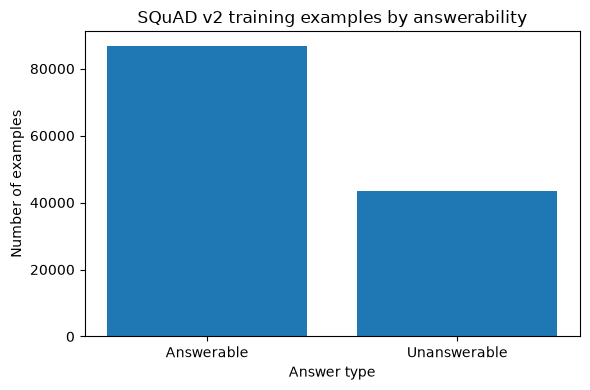

In [4]:
# Summarize answerability to demonstrate understanding of SQuAD v2.
def is_unanswerable(example):
    # In SQuAD v2, an empty answer-text list indicates an unanswerable question.
    return len(example["answers"]["text"]) == 0

train_answerability = Counter(
    "Unanswerable" if is_unanswerable(row) else "Answerable"
    for row in dataset["train"]
)

answerability_df = pd.DataFrame(
    [{"Answer type": label, "Count": count}
     for label, count in train_answerability.items()]
)
display(answerability_df)

# A simple chart is included because answerability is central to this dataset.
plt.figure(figsize=(6, 4))
plt.bar(answerability_df["Answer type"], answerability_df["Count"])
plt.title("SQuAD v2 training examples by answerability")
plt.ylabel("Number of examples")
plt.xlabel("Answer type")
plt.tight_layout()
plt.show()


## 3. Prepare context documents for retrieval

For retrieval, the passage in `context` is the knowledge source. Multiple questions can refer to the same passage, so indexing a copy of the context for every question would create unnecessary duplicates. This section deduplicates contexts and preserves useful metadata.

**Resource note:** The complete training split can be indexed, but embedding every passage can take time and memory. `MAX_CONTEXTS` lets you start with a smaller corpus. Set it to `None` to index every unique training context after confirming that your machine can handle it. The corpus size used for the run is printed below and should be reported in your submission.


In [5]:
# Configuration: begin with a smaller corpus for a faster first run.
# Increase this value or set it to None to use all unique training contexts.
MAX_CONTEXTS = 3000

train_split = dataset["train"]
unique_contexts = {}
for row in train_split:
    context = row["context"].strip()
    if context and context not in unique_contexts:
        unique_contexts[context] = {
            "title": row["title"],
            "source_id": row["id"],
        }

all_context_items = list(unique_contexts.items())
if MAX_CONTEXTS is not None:
    all_context_items = all_context_items[:MAX_CONTEXTS]

contexts = []
for context, metadata in all_context_items:
    contexts.append({
        "context": context,
        "title": metadata["title"],
        "source_id": metadata["source_id"],
    })

print("Unique contexts found in training split:", len(unique_contexts))
print("Contexts selected for the vector index:", len(contexts))
print("\\nExample context:")
print(textwrap.shorten(contexts[0]["context"], width=500, placeholder="..."))
print("Example metadata:", {
    "title": contexts[0]["title"],
    "source_id": contexts[0]["source_id"]
})


Unique contexts found in training split: 19029
Contexts selected for the vector index: 3000
\nExample context:
Beyoncé Giselle Knowles-Carter (/biːˈjɒnseɪ/ bee-YON-say) (born September 4, 1981) is an American singer, songwriter, record producer and actress. Born and raised in Houston, Texas, she performed in various singing and dancing competitions as a child, and rose to fame in the late 1990s as lead singer of R&B girl-group Destiny's Child. Managed by her father, Mathew Knowles, the group became one of the world's best-selling girl groups of all time. Their hiatus saw the release of Beyoncé's debut...
Example metadata: {'title': 'Beyoncé', 'source_id': '56be85543aeaaa14008c9063'}


## 4. Build semantic embeddings and a FAISS index

`all-MiniLM-L6-v2` is a compact Sentence Transformers model that maps text into dense vectors. We normalize the vectors and use FAISS inner-product search; with normalized vectors, inner product corresponds to cosine similarity. The retriever will return the top-*k* passages whose vectors are most similar to the question vector.

The embedding model is used for retrieval only. It does not generate the final answer.


In [6]:
# Load a lightweight sentence-embedding model.
embedding_model_name = "sentence-transformers/all-MiniLM-L6-v2"
embedding_model = SentenceTransformer(embedding_model_name)

context_texts = [item["context"] for item in contexts]

# Encode the contexts in batches to avoid sending the entire corpus at once.
context_embeddings = embedding_model.encode(
    context_texts,
    batch_size=64,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True,
).astype("float32")

# Build a FAISS index for cosine-similarity search using normalized vectors.
embedding_dimension = context_embeddings.shape[1]
faiss_index = faiss.IndexFlatIP(embedding_dimension)
faiss_index.add(context_embeddings)

print("Embedding model:", embedding_model_name)
print("Embedding matrix shape:", context_embeddings.shape)
print("Number of indexed vectors:", faiss_index.ntotal)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/47 [00:00<?, ?it/s]

Embedding model: sentence-transformers/all-MiniLM-L6-v2
Embedding matrix shape: (3000, 384)
Number of indexed vectors: 3000


In [7]:
# Retrieve the top-k contexts for a question.
def retrieve_contexts(question, k=4):
    # Encode the query using the same embedding model as the indexed contexts.
    query_embedding = embedding_model.encode(
        [question],
        convert_to_numpy=True,
        normalize_embeddings=True,
    ).astype("float32")

    # FAISS returns similarity scores and row positions in descending score order.
    scores, indices = faiss_index.search(query_embedding, k)

    results = []
    for score, idx in zip(scores[0], indices[0]):
        if idx < 0:  # FAISS can return -1 when fewer than k results are available.
            continue
        result = contexts[int(idx)].copy()
        result["similarity"] = float(score)
        results.append(result)
    return results


# Inspect retrieval before adding generation; this helps isolate retrieval errors.
retrieval_question = "What is the main purpose of the SQuAD dataset?"
retrieved = retrieve_contexts(retrieval_question, k=3)

print("Question:", retrieval_question)
for rank, item in enumerate(retrieved, start=1):
    print(f"\\nRank {rank} | cosine similarity: {item['similarity']:.3f}")
    print("Title:", item["title"])
    print("Context:", textwrap.shorten(item["context"], width=450, placeholder="..."))


Question: What is the main purpose of the SQuAD dataset?
\nRank 1 | cosine similarity: 0.368
Title: Canadian_Armed_Forces
Context: Currently, the Regular Force component of the Army consists of three field-ready brigade groups: 1 Canadian Mechanized Brigade Group, at CFB Edmonton and CFB Shilo; 2 Canadian Mechanized Brigade Group, at CFB Petawawa and CFB Gagetown; and 5 Canadian Mechanized Brigade Group, at CFB Valcartier and Quebec City. Each contains one regiment each of artillery, armour, and combat engineers, three battalions of infantry (all scaled in the British...
\nRank 2 | cosine similarity: 0.348
Title: Canadian_Armed_Forces
Context: Among other things, the Information Management Group is responsible for the conduct of electronic warfare and the protection of the Armed Forces' communications and computer networks. Within the group, this operational role is fulfilled by the Canadian Forces Information Operations Group, headquartered at CFS Leitrim in Ottawa, which operates the

## 5. Load a lightweight open-source answer-generation model

`google/flan-t5-small` is an open model that can run locally on modest hardware. It is a sequence-to-sequence model, so the correct Transformers class is `AutoModelForSeq2SeqLM`. A small model may produce weak or incorrect answers; the sanity check below is deliberately included so that generation quality is tested before evaluating the full pipeline.


In [8]:
# Load tokenizer and model weights from Hugging Face.
generation_model_name = "google/flan-t5-small"
tokenizer = AutoTokenizer.from_pretrained(generation_model_name)
generation_model = AutoModelForSeq2SeqLM.from_pretrained(generation_model_name)

# Use GPU when available; otherwise run on CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
generation_model = generation_model.to(device)
generation_model.eval()

print("Generation model:", generation_model_name)
print("Device:", device)


Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Generation model: google/flan-t5-small
Device: cpu


In [9]:
def generate_answer(question, retrieved_items, max_input_tokens=512, max_new_tokens=64):
    # Combine retrieved passages into one evidence block. Limit the number of
    # passages so that the prompt remains manageable for this small model.
    evidence_blocks = []
    for rank, item in enumerate(retrieved_items, start=1):
        evidence_blocks.append(
            f"[Passage {rank}] {item['context']}"
        )
    context_text = "\\n\\n".join(evidence_blocks)

    prompt = f"""Answer the question using only the evidence below.
If the evidence does not contain the answer, respond exactly:
Not answerable from the provided context.

Evidence:
{context_text}

Question: {question}
Answer:"""

    # Truncation is a safeguard against exceeding the model's input limit.
    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=max_input_tokens,
    ).to(device)

    with torch.no_grad():
        output_ids = generation_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            num_beams=4,
        )

    answer = tokenizer.decode(output_ids[0], skip_special_tokens=True).strip()
    return answer if answer else "No answer generated."


# Sanity check with a simple, known fact before running the RAG examples.
sanity_context = [{
    "context": "The capital of France is Paris.",
    "title": "Sanity check",
    "source_id": "sanity",
    "similarity": 1.0,
}]
sanity_answer = generate_answer("What is the capital of France?", sanity_context)
print("Sanity-check answer:", sanity_answer)
print("Expected key information: Paris")


Sanity-check answer: Paris
Expected key information: Paris


## 6. End-to-end RAG function

The function below retrieves relevant passages and then asks the language model to answer using only those passages. It returns the question, answer, and retrieval results so that each answer can be checked against its evidence.


In [10]:
def answer_question(question, k=4):
    # Stage 1: retrieve passages that are semantically similar to the question.
    retrieved_items = retrieve_contexts(question, k=k)

    # Stage 2: generate an answer grounded in the retrieved evidence.
    answer = generate_answer(question, retrieved_items)

    return {
        "question": question,
        "answer": answer,
        "retrieved_contexts": retrieved_items,
    }


def display_rag_result(result):
    print("QUESTION:")
    print(result["question"])
    print("\\nGENERATED ANSWER:")
    print(result["answer"])
    print("\\nRETRIEVED EVIDENCE:")
    for rank, item in enumerate(result["retrieved_contexts"], start=1):
        print(f"\\nPassage {rank} | similarity={item['similarity']:.3f}")
        print("Title:", item["title"])
        print(textwrap.shorten(item["context"], width=700, placeholder="..."))


## 7. Qualitative evaluation using SQuAD v2 examples

We select answerable and unanswerable examples from the indexed training corpus so the corresponding passages are available for inspection. This is a qualitative demonstration of the pipeline, not a held-out benchmark or a measure of generalization. A more rigorous evaluation would use a larger held-out set and report retrieval and answer-quality metrics.

The following sample includes both answerable and unanswerable examples. Results can vary with the chosen corpus size, model versions, and hardware. Do not edit generated outputs to make them look correct; discuss incorrect outputs as evaluation findings.


In [11]:
# Select examples whose source context is actually present in the vector index.
# This lets us compare generation against the known SQuAD v2 reference answers.
indexed_context_set = {item["context"] for item in contexts}
evaluation_rows = dataset["train"]

answerable_examples = [
    row for row in evaluation_rows
    if not is_unanswerable(row) and row["context"].strip() in indexed_context_set
]
unanswerable_examples = [
    row for row in evaluation_rows
    if is_unanswerable(row) and row["context"].strip() in indexed_context_set
]

print("Matching answerable examples:", len(answerable_examples))
print("Matching unanswerable examples:", len(unanswerable_examples))

# Select up to two examples of each type reproducibly. These are qualitative
# demonstrations from the training split, not a held-out benchmark.
rng = random.Random(RANDOM_SEED)
evaluation_examples = []
for case_type, candidates in [
    ("Answerable", answerable_examples),
    ("Unanswerable", unanswerable_examples),
]:
    if candidates:
        selected = rng.sample(candidates, k=min(2, len(candidates)))
        evaluation_examples.extend((case_type, row) for row in selected)

print("Selected evaluation examples:", len(evaluation_examples))
print("Note: these examples are for qualitative inspection, not a statistically valid benchmark.")

if not evaluation_examples:
    print(
        "No examples matched the current index. Increase MAX_CONTEXTS or "
        "set MAX_CONTEXTS = None, then rerun the context preparation, embedding, "
        "index, and evaluation cells."
    )


Matching answerable examples: 13156
Matching unanswerable examples: 4395
Selected evaluation examples: 4
Note: these examples are for qualitative inspection, not a statistically valid benchmark.


In [12]:
# Run the selected examples and preserve both model output and reference answers.
evaluation_results = []

for case_type, row in evaluation_examples:
    result = answer_question(row["question"], k=4)
    reference_answers = row["answers"]["text"]

    evaluation_results.append({
        "case_type": case_type,
        "question": row["question"],
        "reference_answers": reference_answers,
        "generated_answer": result["answer"],
        "expected_context": row["context"],
        "retrieved_contexts": result["retrieved_contexts"],
        "result": result,
    })

    print("\\n" + "=" * 90)
    print("CASE TYPE:", case_type)
    print("REFERENCE ANSWER(S):", reference_answers if reference_answers else
          "No answer (SQuAD v2 unanswerable example)")
    display_rag_result(result)


\n==========================================================================================
CASE TYPE: Answerable
REFERENCE ANSWER(S): ['forehead']
QUESTION:
What part of his mom's head would Bell talk into?
\nGENERATED ANSWER:
Bell, at the receiving end of the wire, heard the overtones of the reed.
\nRETRIEVED EVIDENCE:
\nPassage 1 | similarity=0.614
Title: Alexander_Graham_Bell
From his early years, Bell showed a sensitive nature and a talent for art, poetry, and music that was encouraged by his mother. With no formal training, he mastered the piano and became the family's pianist. Despite being normally quiet and introspective, he reveled in mimicry and "voice tricks" akin to ventriloquism that continually entertained family guests during their occasional visits. Bell was also deeply affected by his mother's gradual deafness, (she began to lose her hearing when he was 12) and learned a manual finger language so he could sit at her side and tap out silently the conversations swirlin

## 8. Qualitative evaluation and limitations

Review the printed examples and complete the evaluation table below using outputs from your own run. For each example, check the top retrieved passage(s), the generated answer, and the SQuAD v2 reference answer(s).

Use **Yes**, **Partial**, or **No** in the two assessment columns. In the notes column, cite a concrete observation (for example, the correct evidence ranked second, the answer omitted a key detail, or the model guessed on an unanswerable question). Ratings are intentionally left for you to complete after inspecting actual outputs; they should not be invented automatically.


In [13]:
# Create a compact evaluation worksheet from the actual run.
# Fill in the three assessment columns after inspecting each generated answer.
evaluation_table = pd.DataFrame([
    {
        "Case": item["case_type"],
        "Question": item["question"],
        "Generated answer": item["generated_answer"],
        "Reference answer(s)": " | ".join(item["reference_answers"])
            if item["reference_answers"] else "Unanswerable",
        "Retrieval relevant? (Yes/Partial/No)": "",
        "Answer grounded? (Yes/Partial/No)": "",
        "Notes / limitation": "",
    }
    for item in evaluation_results
])

display(evaluation_table)


,Case,Question,Generated answer,Reference answer(s),Retrieval relevant? (Yes/Partial/No),Answer grounded? (Yes/Partial/No),Notes / limitation
0,Answerable,What part of his mom's head would Bell talk into?,"Bell, at the receiving end of the wire, heard ...",forehead,,,
1,Answerable,What specific problem caused the issue with ba...,"West's fourth studio album, 808s & Heartbreak ...",clipping,,,
2,Unanswerable,The McClintock estate settled the issue with w...,MGM and the McClory estate formally settled th...,Unanswerable,,,
3,Unanswerable,What language is spoken in both Serbia and Cro...,Serbian,Unanswerable,,,


## 9. Conclusion

After running the notebook, write a concise conclusion in your own words. Address each point:

1. **Dataset:** Explain the SQuAD v2 fields and how empty `answers["text"]` identifies unanswerable questions. Mention which Hugging Face loading route succeeded in your run.
2. **Retrieval:** Explain how `all-MiniLM-L6-v2` embeds questions and passages, and how FAISS returns the top-*k* contexts by cosine similarity.
3. **Generation:** State whether `google/flan-t5-small` produced coherent answers grounded in retrieved evidence. Use at least one observed example.
4. **Evaluation:** Compare answerable and unanswerable cases. Report where retrieval or generation failed, if applicable.
5. **Improvements:** Identify a concrete next step, such as indexing more contexts, evaluating more examples from the validation split, adding a reranker, or testing a stronger small open model.
